<a href="https://colab.research.google.com/github/DanielLucero25/CSC349/blob/main/HW7/wine_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSC 349 HW7: Wine Clustering

[Open in Colab](https://colab.research.google.com/github/DanielLucero25/CSC349/blob/main/HW7/wine_clustering.ipynb)

## Task 1: Load and scale the data

I load the Wine dataset directly from Scikit-Learn and put its 13 chemical measurements into a DataFrame. I print the number of rows and features, summary statistics and missing value counts.The target column is kept out of the clustering features.

StandardScaler subtracts each feature's mean and divides by its standard deviation. This keeps measurements with large values from controlling the distance calculations. The two box plots show all 13 feature distributions before and after scaling. Scaling changes their units but does not remove unusual values or make every distribution normal.

Scikit-Learn version: 1.6.1
Feature dimensions: (178, 13)


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


Missing values:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64


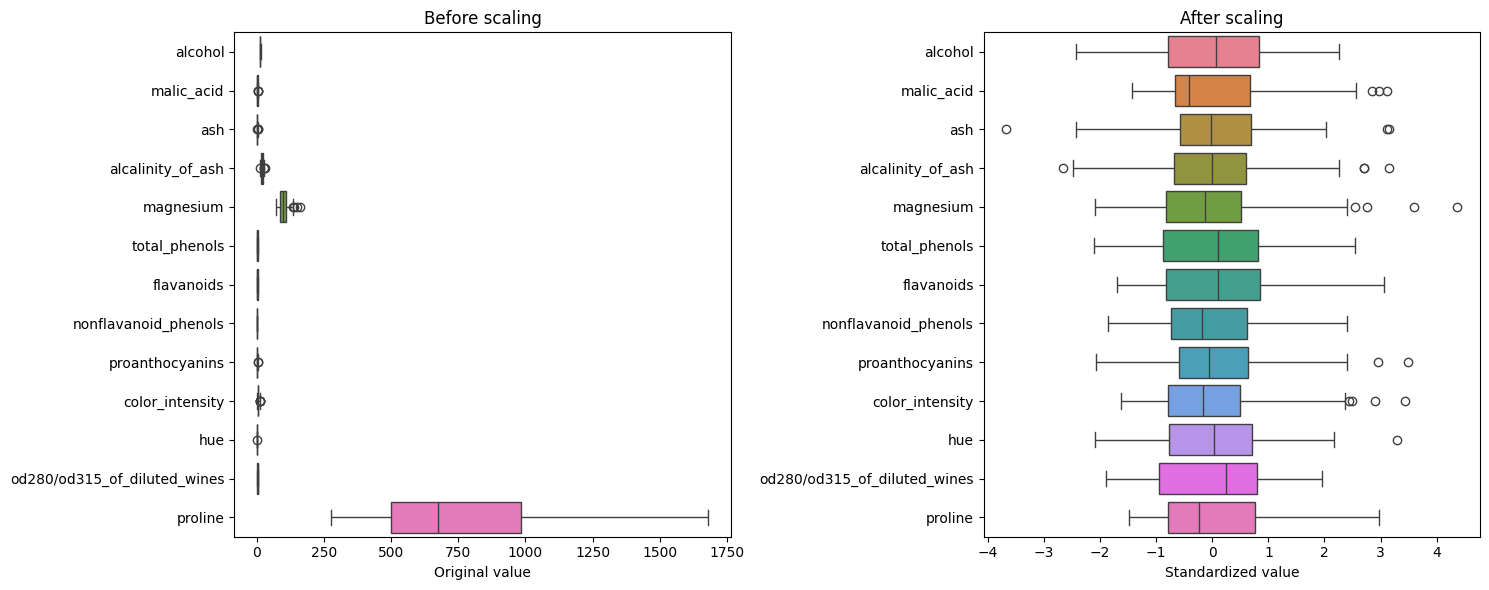

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, DBSCAN, HDBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from scipy.spatial import Voronoi, voronoi_plot_2d
from scipy.cluster.hierarchy import linkage, dendrogram
from matplotlib.patches import Rectangle

print('Scikit-Learn version:', sklearn.__version__)
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target
print('Feature dimensions:', X.shape)
display(X.describe().T)
print('Missing values:')
print(X.isna().sum())
X.assign(target=y).to_csv('wine.csv', index=False)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.boxplot(data=X, orient='h', ax=axes[0])
sns.boxplot(data=scaled_df, orient='h', ax=axes[1])
axes[0].set(title='Before scaling', xlabel='Original value')
axes[1].set(title='After scaling', xlabel='Standardized value')
plt.tight_layout()
plt.show()

## Task 2: Choose the number of clusters

I fit K-Means on all 13 scaled features for k from 1 through 10. Inertia measures the sum of squared distances from samples to their assigned centers. It always decreases as more centers are added, so I look for an elbow where the improvement begins to slow down.

To make the elbow choice repeatable, I normalize both axes and choose the point farthest below the straight line joining the first and last inertia values. This is a simple elbow estimate, not proof of the correct number of groups. I calculate silhouette scores for k from 2 through 10 and select the largest score. A larger silhouette score means better separation compared with the spread inside each cluster. I print both suggested values and keep a separate 13-feature model with k=3 for later tasks.

Optimal k suggested by elbow estimate: 3
Optimal k suggested by silhouette: 3


,k,inertia,silhouette
0,1,2314.0000,NaN
1,2,1658.7589,0.2593
2,3,1277.9285,0.2849
3,4,1175.4283,0.2602
4,5,1109.5127,0.2016
5,6,1046.0023,0.2372
6,7,981.5952,0.2036
7,8,935.2012,0.1570
8,9,889.8929,0.1499
9,10,845.8952,0.1436


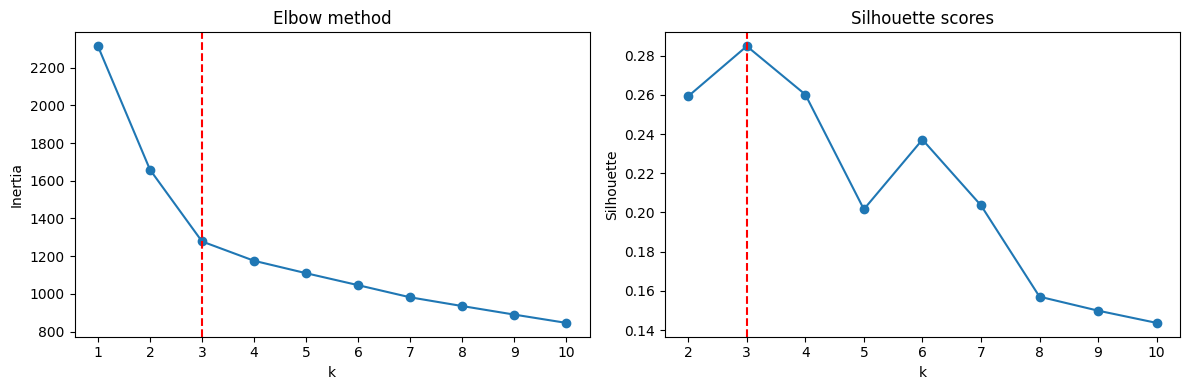

In [ ]:
ks = np.arange(1, 11)
inertias = []
silhouettes = []
for k in ks:
    model = KMeans(n_clusters=int(k), random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    if k >= 2:
        silhouettes.append(silhouette_score(X_scaled, labels))
x_normal = (ks - ks.min()) / (ks.max() - ks.min())
y_normal = (np.array(inertias) - min(inertias)) / (max(inertias) - min(inertias))
elbow_k = int(ks[np.argmax((1 - x_normal) - y_normal)])
silhouette_k = int(ks[1:][np.argmax(silhouettes)])
print('Optimal k suggested by elbow estimate:', elbow_k)
print('Optimal k suggested by silhouette:', silhouette_k)
display(pd.DataFrame({'k': ks, 'inertia': inertias,
                      'silhouette': [np.nan] + silhouettes}).round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inertias, 'o-')
axes[0].axvline(elbow_k, color='red', linestyle='--')
axes[0].set(title='Elbow method', xlabel='k', ylabel='Inertia', xticks=ks)
axes[1].plot(ks[1:], silhouettes, 'o-')
axes[1].axvline(silhouette_k, color='red', linestyle='--')
axes[1].set(title='Silhouette scores', xlabel='k', ylabel='Silhouette', xticks=ks[1:])
plt.tight_layout()
plt.show()
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_scaled)
kmeans_labels = kmeans.labels_

## Task 3: PCA and Voronoi boundaries

I use PCA to show the 13 scaled measurements in two dimensions and print how much variance those two components keep. I fit a new K-Means model with three clusters only on this 2D projection, as requested for this visualization. The model from Task 2 still uses all 13 features.

The colored background gives each location to its nearest 2D center. The Voronoi lines mark where locations are equally close to neighboring centers. The dots show wines and the black X markers show centers. This plot explains the 2D model, so its assignments do not have to match the 13-feature model.

Variance kept by two components: 0.5541


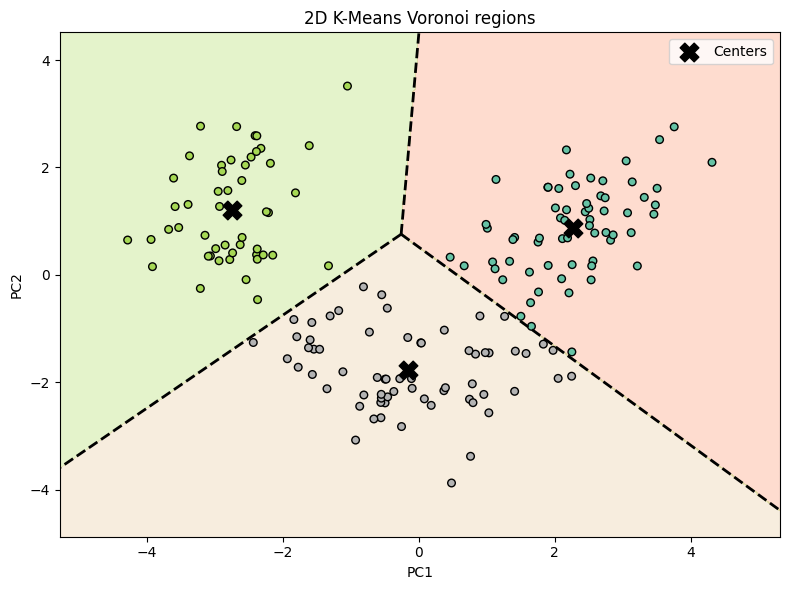

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print('Variance kept by two components:', round(pca.explained_variance_ratio_.sum(), 4))
kmeans_2d = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_pca)
centers = kmeans_2d.cluster_centers_
xmin, ymin = X_pca.min(axis=0) - 1
xmax, ymax = X_pca.max(axis=0) + 1
xx, yy = np.meshgrid(np.linspace(xmin, xmax, 300), np.linspace(ymin, ymax, 300))
regions = kmeans_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(8, 6))
ax.contourf(xx, yy, regions, levels=[-0.5, 0.5, 1.5, 2.5], cmap='Set2', alpha=0.3)
voronoi_plot_2d(Voronoi(centers), ax=ax, show_points=False, show_vertices=False,
                line_colors='black', line_width=2)
ax.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_2d.labels_, cmap='Set2', edgecolor='black', s=30)
ax.scatter(centers[:, 0], centers[:, 1], marker='X', color='black', s=180, label='Centers')
ax.set(xlim=(xmin, xmax), ylim=(ymin, ymax), xlabel='PC1', ylabel='PC2',
       title='2D K-Means Voronoi regions')
ax.legend()
plt.tight_layout()
plt.show()

## Task 4: Distances to the cluster centers

I use the 13-feature K-Means model to select five wines without looking at their actual classes. Three wines are the closest samples to each center. The other two have the smallest gap between their nearest and second-nearest centers, which gives examples with less clear assignments.

The transform method returns each selected wine's distance to all three centers. Smaller values mean a closer match. The table prints the hard assignment, and red boxes in the heatmap highlight the minimum in each row. These distances provide a soft description of similarity, but they are not probabilities.

,Cluster 0,Cluster 1,Cluster 2,hard_cluster
Wine 106,1.548,4.268,4.305,0
Wine 148,4.495,1.079,5.298,1
Wine 48,3.815,4.869,1.343,2
Wine 61,3.521,3.397,5.250,1
Wine 121,6.327,7.476,6.162,2


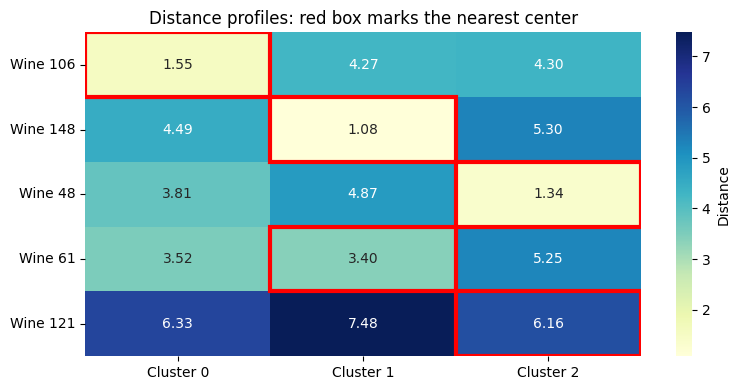

In [ ]:
all_distances = kmeans.transform(X_scaled)
selected = list(np.argmin(all_distances, axis=0))
sorted_distances = np.sort(all_distances, axis=1)
gaps = sorted_distances[:, 1] - sorted_distances[:, 0]
for row in np.argsort(gaps):
    if int(row) not in selected:
        selected.append(int(row))
    if len(selected) == 5:
        break
distances = kmeans.transform(X_scaled[selected])
distance_df = pd.DataFrame(distances, index=[f'Wine {i}' for i in selected],
                           columns=['Cluster 0', 'Cluster 1', 'Cluster 2'])
display(distance_df.assign(hard_cluster=np.argmin(distances, axis=1)).round(3))
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(distance_df, annot=True, fmt='.2f', cmap='YlGnBu', ax=ax,
            cbar_kws={'label': 'Distance'})
for row, column in enumerate(np.argmin(distances, axis=1)):
    ax.add_patch(Rectangle((column, row), 1, 1, fill=False, edgecolor='red', linewidth=3))
ax.set_title('Distance profiles: red box marks the nearest center')
plt.tight_layout()
plt.show()

## Task 5: DBSCAN

DBSCAN uses eps as the neighborhood radius and min_samples as the minimum number of nearby samples needed for a core point, including the point itself. I try four radii and three minimum sample counts in the full 13-feature space. I print the cluster count, noise count, coverage and silhouette score for every setting. Noise is excluded from silhouette because it is not one real cluster.

I choose the highest silhouette among settings with at least two clusters and at least half of the wines assigned. The coverage rule avoids selecting a result that keeps only a few easy samples. This small search uses no actual wine labels. On the PCA plot, large colored circles are core points, small colored triangles are border points and black crosses are noise. The plot is a projection of the 13-feature assignments.

,eps,min_samples,clusters,noise,coverage,silhouette
0,1.5,3,8,147,0.1742,0.3311
1,1.5,5,0,178,0.0000,NaN
2,1.5,10,0,178,0.0000,NaN
3,2.0,3,5,64,0.6404,0.2113
4,2.0,5,5,85,0.5225,0.2405
5,2.0,10,1,139,0.2191,NaN
6,2.5,3,1,23,0.8708,NaN
7,2.5,5,1,24,0.8652,NaN
8,2.5,10,2,32,0.8202,0.3228
9,3.0,3,2,7,0.9607,0.2392


Selected eps: 2.5 min_samples: 10
Clusters and noise: (2, 32)


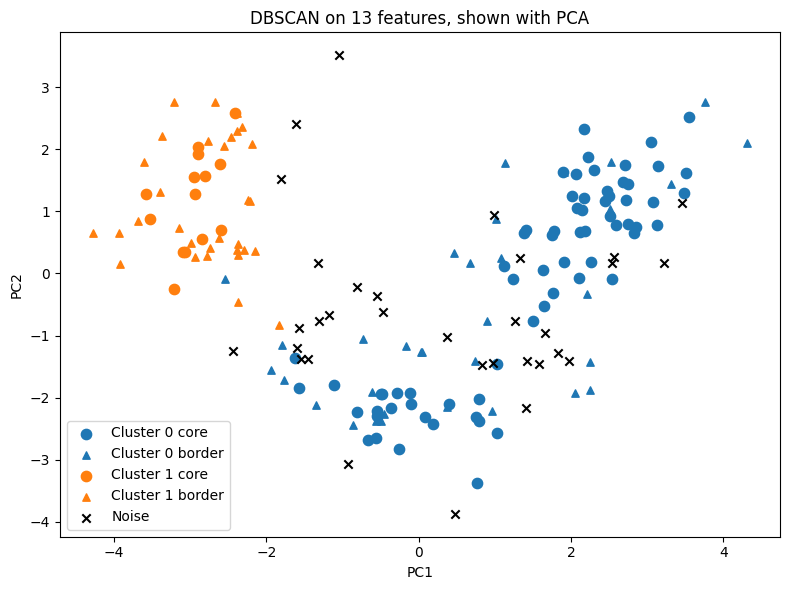

First five noise row indices: [13, 25, 50, 59, 60]


In [ ]:
def cluster_stats(labels):
    keep = labels != -1
    count = len(np.unique(labels[keep]))
    score = np.nan
    if 2 <= count < keep.sum():
        score = silhouette_score(X_scaled[keep], labels[keep])
    return count, int((~keep).sum()), float(keep.mean()), score

trials = []
for eps in [1.5, 2.0, 2.5, 3.0]:
    for min_samples in [3, 5, 10]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        count, noise, coverage, score = cluster_stats(labels)
        trials.append([eps, min_samples, count, noise, coverage, score])
trial_df = pd.DataFrame(trials, columns=['eps', 'min_samples', 'clusters', 'noise', 'coverage', 'silhouette'])
display(trial_df.round(4))
valid = trial_df[(trial_df.clusters >= 2) & (trial_df.coverage >= 0.5)]
best = valid.sort_values('silhouette', ascending=False).iloc[0]
dbscan = DBSCAN(eps=float(best.eps), min_samples=int(best.min_samples)).fit(X_scaled)
dbscan_labels = dbscan.labels_
print('Selected eps:', dbscan.eps, 'min_samples:', dbscan.min_samples)
print('Clusters and noise:', cluster_stats(dbscan_labels)[:2])
core = np.zeros(len(X), dtype=bool)
core[dbscan.core_sample_indices_] = True
fig, ax = plt.subplots(figsize=(8, 6))
for label in sorted(set(dbscan_labels) - {-1}):
    color = plt.get_cmap('tab10')(label % 10)
    for mask, marker, size, kind in [(core, 'o', 55, 'core'), (~core, '^', 28, 'border')]:
        rows = (dbscan_labels == label) & mask
        ax.scatter(X_pca[rows, 0], X_pca[rows, 1], color=color, marker=marker,
                   s=size, label=f'Cluster {label} {kind}')
noise = dbscan_labels == -1
ax.scatter(X_pca[noise, 0], X_pca[noise, 1], color='black', marker='x', label='Noise')
ax.set(title='DBSCAN on 13 features, shown with PCA', xlabel='PC1', ylabel='PC2')
ax.legend()
plt.tight_layout()
plt.show()
print('First five noise row indices:', np.flatnonzero(noise)[:5].tolist())

## Task 6: HDBSCAN

I fit Scikit-Learn's HDBSCAN using min_cluster_size=5 and min_samples=5 on all 13 scaled features. It considers groups across different density levels and chooses clusters that persist across those levels. It can leave samples unassigned instead of forcing every wine into a group.

I print the number of clusters and noise points, then display the assignments on the same PCA projection. Colored circles are assigned samples and black crosses are noise. This lets me compare the density methods using the same view, although distance in this view does not show all 13 dimensions.

HDBSCAN clusters and noise: (2, 58)


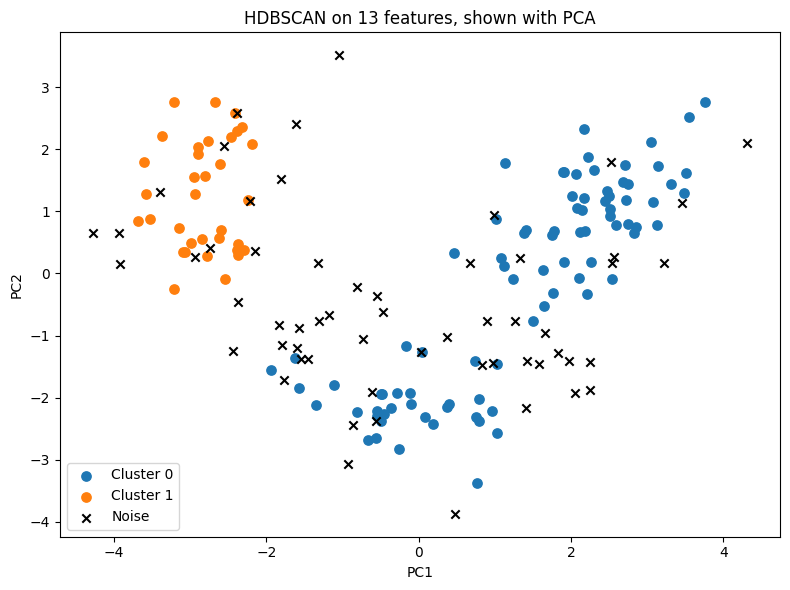

First five noise row indices: [13, 14, 25, 39, 41]


In [ ]:
hdbscan = HDBSCAN(min_cluster_size=5, min_samples=5, copy=True).fit(X_scaled)
hdbscan_labels = hdbscan.labels_
print('HDBSCAN clusters and noise:', cluster_stats(hdbscan_labels)[:2])
fig, ax = plt.subplots(figsize=(8, 6))
for label in sorted(set(hdbscan_labels) - {-1}):
    rows = hdbscan_labels == label
    ax.scatter(X_pca[rows, 0], X_pca[rows, 1], s=45, label=f'Cluster {label}')
noise = hdbscan_labels == -1
ax.scatter(X_pca[noise, 0], X_pca[noise, 1], color='black', marker='x', label='Noise')
ax.set(title='HDBSCAN on 13 features, shown with PCA', xlabel='PC1', ylabel='PC2')
ax.legend()
plt.tight_layout()
plt.show()
print('First five noise row indices:', np.flatnonzero(noise)[:5].tolist())

## Task 7: Single-linkage dendrogram

I calculate a single-linkage matrix using Euclidean distances between the scaled wines. Single linkage joins groups using the closest pair of members. The dendrogram shows every sample as a leaf, with row indices as labels. The height of a join shows the distance needed to connect the groups. A chain of nearby samples can connect larger groups even when their overall shapes are different.

This illustrates a hierarchy of merges, but it is not HDBSCAN's exact hierarchy. HDBSCAN first adjusts distances using local density through mutual reachability. It then condenses the hierarchy using the minimum cluster size and extracts stable clusters across density levels. It does not simply choose one horizontal cut in this ordinary Euclidean dendrogram.

Linkage matrix dimensions: (177, 4)


,group_1,group_2,distance,samples
0,9.0,47.0,1.164114,2.0
1,131.0,133.0,1.191602,2.0
2,11.0,12.0,1.209356,2.0
3,15.0,53.0,1.225510,2.0
4,92.0,107.0,1.245388,2.0


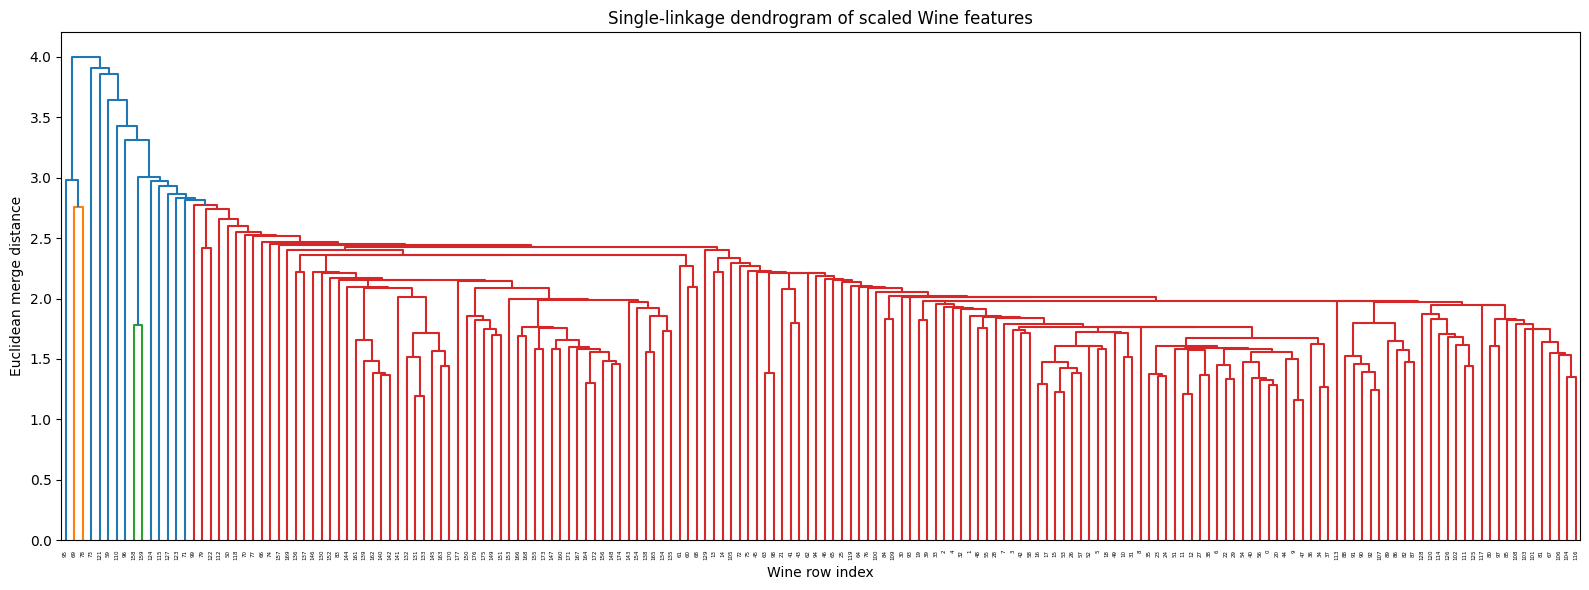

In [ ]:
linkage_matrix = linkage(X_scaled, method='single', metric='euclidean')
print('Linkage matrix dimensions:', linkage_matrix.shape)
display(pd.DataFrame(linkage_matrix[:5], columns=['group_1', 'group_2', 'distance', 'samples']))
plt.figure(figsize=(16, 6))
dendrogram(linkage_matrix, labels=[str(i) for i in range(len(X))], leaf_rotation=90, leaf_font_size=4)
plt.title('Single-linkage dendrogram of scaled Wine features')
plt.xlabel('Wine row index')
plt.ylabel('Euclidean merge distance')
plt.tight_layout()
plt.show()

## Task 8: Predict cultivars using cluster labels

I reuse the assignments from the three 13-feature clustering models as requested. Each classifier receives only one categorical input, the cluster label. One-hot encoding prevents cluster numbers from being treated as ordered measurements. Noise label -1 is kept as its own category and is included in test accuracy. Logistic regression learns how the cluster categories relate to the true wine classes using only the training labels.

I use the same stratified 80/20 split for all three classifiers. The table and plots compare test accuracy and silhouette, and the class count tables show when one cluster mixes cultivars. Silhouette is measured in the original 13 scaled dimensions and excludes noise. I also print coverage, since a score based on fewer retained samples is not directly comparable to a score based on every wine.

This is a transductive experiment. That means the earlier scaling and clustering used all the feature rows, including the test rows, but no actual class labels. Only the supervised classifier is trained on the 80 percent split. This follows the request to reuse the earlier assignments, but it is not a fully independent test on unseen wines and may give an optimistic estimate. A separate future-data experiment would need to split first and fit scaling and clustering only on training rows. DBSCAN and this HDBSCAN implementation do not have a standard predict method for new rows.

Training rows: 142 Test rows: 36
Test class counts: [12 14 10]
K-Means cluster/class counts on the complete dataset:


cultivar,0,1,2
cluster,,,
0,0,65,0
1,0,3,48
2,59,3,0


Test confusion matrix: rows are true classes, columns are predictions
[[12  0  0]
 [ 1 13  0]
 [ 0  0 10]]
DBSCAN cluster/class counts on the complete dataset:


cultivar,0,1,2
cluster,,,
-1,3,25,4
0,56,45,0
1,0,1,44


Test confusion matrix: rows are true classes, columns are predictions
[[12  0  0]
 [11  3  0]
 [ 0  1  9]]
HDBSCAN cluster/class counts on the complete dataset:


cultivar,0,1,2
cluster,,,
-1,6,37,15
0,53,33,0
1,0,1,33


Test confusion matrix: rows are true classes, columns are predictions
[[11  1  0]
 [ 5  9  0]
 [ 0  3  7]]


,algorithm,accuracy,silhouette,clusters,noise,coverage
0,K-Means,0.9722,0.2849,3,0,1.0000
1,DBSCAN,0.6667,0.3228,2,32,0.8202
2,HDBSCAN,0.7500,0.3524,2,58,0.6742


Training-majority baseline accuracy: 0.3888888888888889


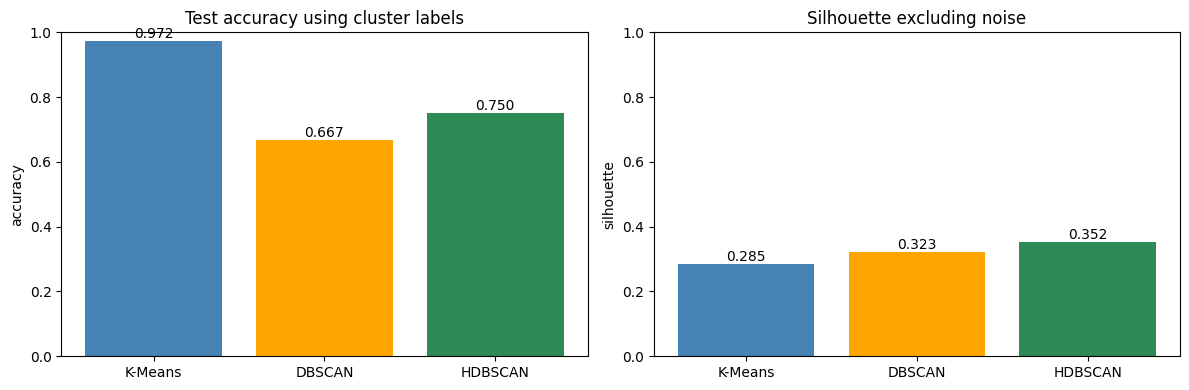

In [ ]:
train_idx, test_idx = train_test_split(np.arange(len(X)), test_size=0.2,
                                      random_state=42, stratify=y)
print('Training rows:', len(train_idx), 'Test rows:', len(test_idx))
print('Test class counts:', np.bincount(y[test_idx]))
assignments = {'K-Means': kmeans_labels, 'DBSCAN': dbscan_labels, 'HDBSCAN': hdbscan_labels}
results = []
for name, labels in assignments.items():
    features = labels.reshape(-1, 1)
    classifier = make_pipeline(OneHotEncoder(handle_unknown='ignore'),
                               LogisticRegression(max_iter=1000, random_state=42))
    classifier.fit(features[train_idx], y[train_idx])
    predictions = classifier.predict(features[test_idx])
    accuracy = accuracy_score(y[test_idx], predictions)
    count, noise, coverage, score = cluster_stats(labels)
    results.append([name, accuracy, score, count, noise, coverage])
    print(name, 'cluster/class counts on the complete dataset:')
    display(pd.crosstab(pd.Series(labels, name='cluster'), pd.Series(y, name='cultivar')))
    print('Test confusion matrix: rows are true classes, columns are predictions')
    print(confusion_matrix(y[test_idx], predictions, labels=[0, 1, 2]))
results_df = pd.DataFrame(results, columns=['algorithm', 'accuracy', 'silhouette', 'clusters', 'noise', 'coverage'])
display(results_df.round(4))
print('Training-majority baseline accuracy:', np.mean(y[test_idx] == np.bincount(y[train_idx]).argmax()))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in zip(axes, ['accuracy', 'silhouette'],
                            ['Test accuracy using cluster labels', 'Silhouette excluding noise']):
    bars = ax.bar(results_df.algorithm, results_df[metric], color=['steelblue', 'orange', 'seagreen'])
    ax.bar_label(bars, fmt='%.3f')
    ax.set(title=title, ylabel=metric, ylim=(0, 1))
plt.tight_layout()
plt.show()

## References

[Scikit-Learn Wine dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html)

[Scikit-Learn clustering guide](https://scikit-learn.org/stable/modules/clustering.html)

[Scikit-Learn HDBSCAN](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.HDBSCAN.html)